In [ ]:
Import library dan loading data

In [1]:
import zipfile
import pandas as pd

with zipfile.ZipFile("archive.zip", "r") as file_zip:
    with file_zip.open("spam.csv") as file:
        df = pd.read_csv(file, encoding="latin-1")

print(df.head())

print("Ukuran dataset:", df.shape)

     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
Ukuran dataset: (5572, 5)


In [ ]:
Membersihkan data

In [2]:
df = df[["v1", "v2"]]

df.columns = ["label", "message"]

df = df.dropna()
df = df.drop_duplicates()

print(df.head())
print("Ukuran setelah dibersihkan:", df.shape)
print(df["label"].value_counts())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Ukuran setelah dibersihkan: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:
Eksplorasi data

label
ham     4516
spam     653
Name: count, dtype: int64


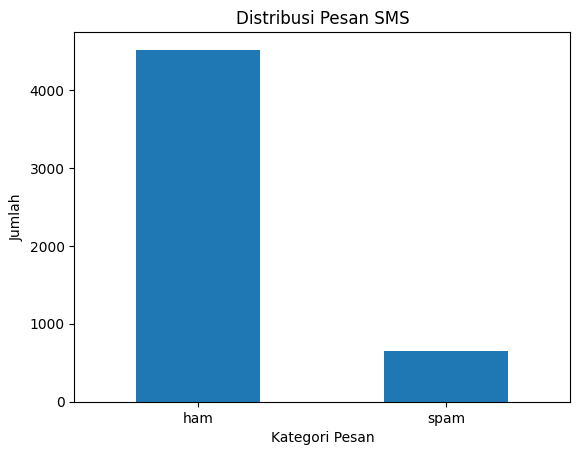

In [3]:
import matplotlib.pyplot as plt

jumlah_label = df["label"].value_counts()

print(jumlah_label)

jumlah_label.plot(kind="bar")
plt.title("Distribusi Pesan SMS")
plt.xlabel("Kategori Pesan")
plt.ylabel("Jumlah")
plt.xticks(rotation=0)
plt.show()


In [ ]:
Transformasi teks dan pembagian data

In [4]:
from sklearn.model_selection import train_test_split

X = df["message"]  
y = df["label"]    

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 4135
Jumlah data testing: 1034


In [ ]:
Membuat dan melatih model

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english"
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Model berhasil dilatih!")


Model berhasil dilatih!


In [ ]:
Menguji dan mengevaluasi model

Akurasi: 96.62 %
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



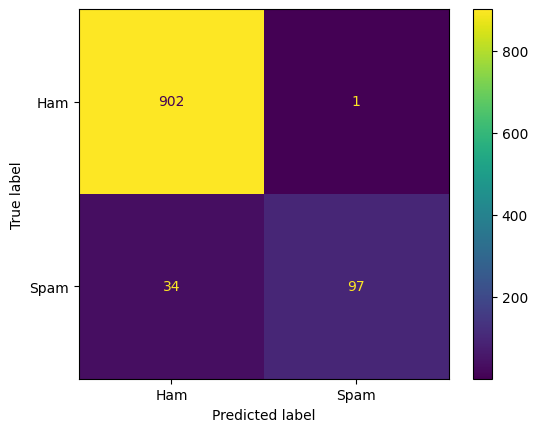

In [6]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)
print("Akurasi:", round(akurasi * 100, 2), "%")

print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test, y_pred, labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)
disp.plot()
plt.show()


In [ ]:
mengembangkan model menjadi program pendeteksi SMS

In [ ]:
1. Menyimpan model

In [7]:
import joblib

joblib.dump(model, "model_spam.pkl")

print("Model berhasil disimpan!")


Model berhasil disimpan!


In [ ]:
2. Membuat program prediksi SMS

In [10]:
import joblib

model = joblib.load("model_spam.pkl")

print("=== DETEKSI SMS SPAM ===")
pesan = input("Masukkan isi pesan SMS: ")

hasil = model.predict([pesan])[0]

if hasil == "spam":
    print("Hasil: PESAN SPAM")
else:
    print("Hasil: PESAN NORMAL (HAM)")


=== DETEKSI SMS SPAM ===


Masukkan isi pesan SMS:  Congratulations! You won a free prize. Call now


Hasil: PESAN SPAM


In [12]:
import os

print(os.path.exists("model_spam.pkl"))
print(os.path.abspath("model_spam.pkl"))

True
C:\Users\TERRA\machine learning\model_spam.pkl
